<a href="https://colab.research.google.com/github/Shivamthakur7500/FireWatchNet/blob/main/07_Prediction_and_Map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np, joblib, geopandas as gpd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
BASE = "/content/drive/MyDrive/FireWatchNet"
LOW, HIGH = 0.3, 0.6
LEVELS = ["Low", "Medium", "High"]
COLORS = {"Low": "#4caf50", "Medium": "#ffb300", "High": "#d32f2f"}
def risk_level(s):
    return pd.cut(s, [-1, LOW, HIGH, 2], labels=LEVELS, right=False)

bundle = joblib.load(f"{BASE}/Models/firewatchnet_model.pkl")
model, FEATURES = bundle["model"], bundle["features"]
print(bundle["note"])

D = pd.read_parquet(f"{BASE}/Data/processed/firewatchnet_dataset.parquet")
D["forecast_date"] = pd.to_datetime(D["forecast_date"])
grid = gpd.read_file(f"{BASE}/Data/processed/Spatial/Uttarakhand_5km_Grid_WGS84.geojson")[["cell_id", "geometry"]]

DEMO = "2024-12-01"
day = D[D.forecast_date == DEMO].copy()
day["score"] = model.predict_proba(day[FEATURES].astype("float32"))[:, 1]
day["risk_level"] = risk_level(day["score"])

P2 = pd.read_parquet(f"{BASE}/Data/processed/predictions_E2.parquet")
P2["forecast_date"] = pd.to_datetime(P2["forecast_date"])
chk = day.merge(P2[P2.forecast_date == DEMO][["cell_id", "p_RandomForest"]], on="cell_id")
print("cells scored:", len(day))
print("saved model reproduces stored predictions:", np.allclose(chk.score, chk.p_RandomForest, atol=1e-6))
print(day.sort_values("score", ascending=False)[["cell_id", "score", "risk_level", "prior_30d_days", "fire_next_7d"]].head(10).to_string(index=False))


Mounted at /content/drive
RandomForest baseline (NOT a ViT-GNN hybrid), trained 2023-01-01..2024-06-23 on a 300k-row sample, 5km grid, target: fire detected in next 7 days
cells scored: 2233
saved model reproduces stored predictions: True
          cell_id    score risk_level  prior_30d_days  fire_next_7d
UK_215000_3290000 0.768483       High             4.0             0
UK_200000_3310000 0.760542       High             2.0             0
UK_220000_3300000 0.759857       High             2.0             0
UK_205000_3285000 0.759224       High             2.0             1
UK_200000_3295000 0.757450       High             2.0             1
UK_220000_3295000 0.753235       High             2.0             0
UK_205000_3300000 0.751765       High             3.0             1
UK_205000_3305000 0.749872       High             3.0             1
UK_215000_3300000 0.748176       High             2.0             0
UK_220000_3305000 0.740372       High             2.0             0



2024-04-10 (E1 model (trained on 2023 only))
        cells  actual_fire_rate
level                          
Low       939             0.012
Medium    745             0.094
High      549             0.231

2024-12-01 (Saved model (trained to Jun 2024))
        cells  actual_fire_rate
level                          
Low      1593             0.011
Medium    553             0.043
High       87             0.230


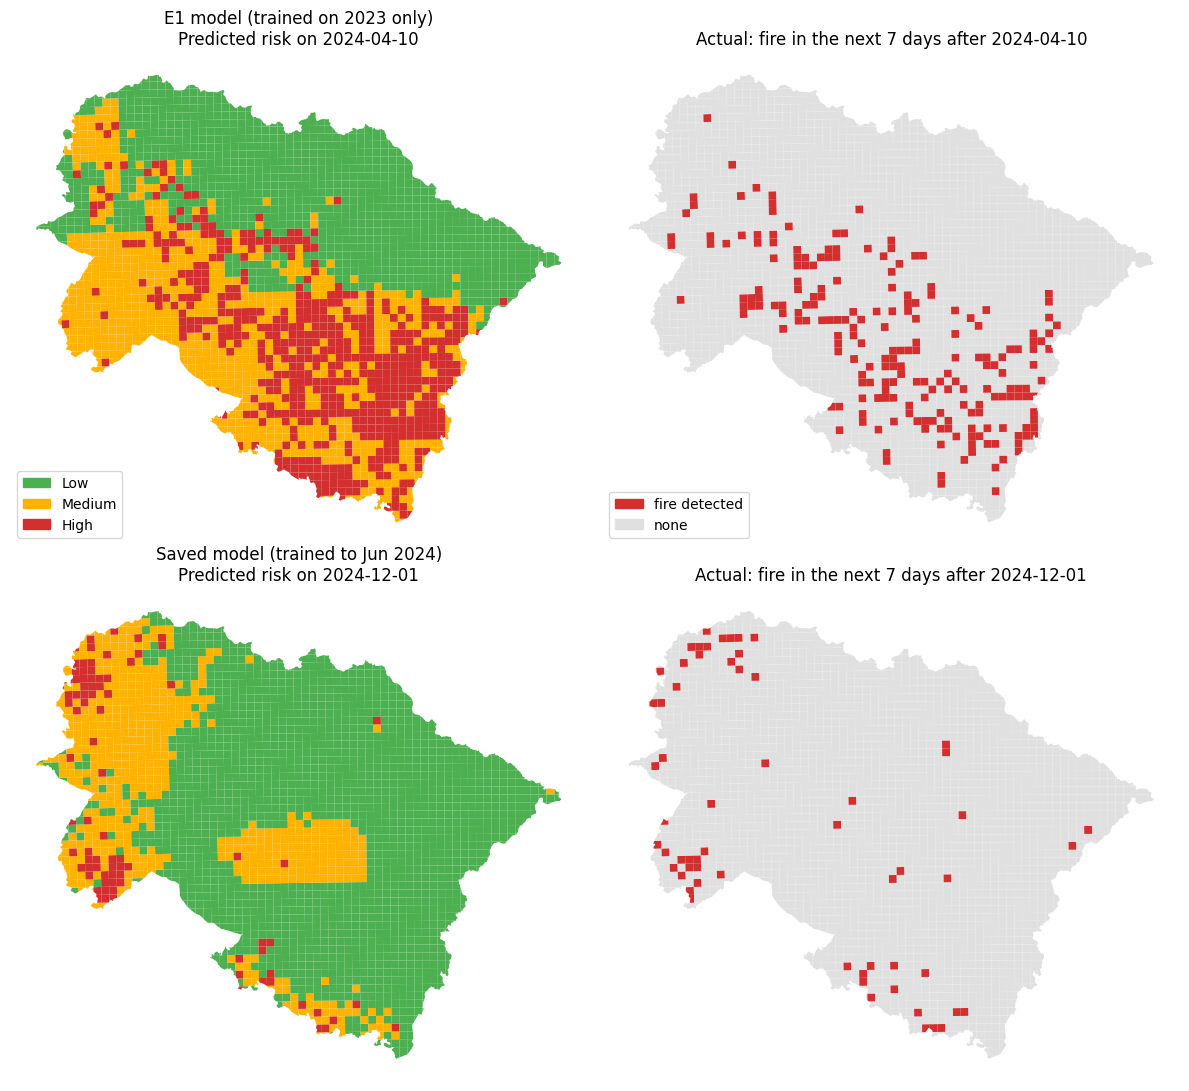

In [ ]:
P1 = pd.read_parquet(f"{BASE}/Data/processed/predictions_E1.parquet")
P1["forecast_date"] = pd.to_datetime(P1["forecast_date"])
panels = [("E1 model (trained on 2023 only)", P1, "2024-04-10"),
          ("Saved model (trained to Jun 2024)", P2, DEMO)]

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for r, (name, P, date) in enumerate(panels):
    d = P[P.forecast_date == date].copy()
    d["level"] = risk_level(d["p_RandomForest"])
    g = grid.merge(d, on="cell_id")
    g.plot(ax=axes[r, 0], color=g["level"].astype(str).map(COLORS), edgecolor="none")
    g.plot(ax=axes[r, 1], color=np.where(g["fire_next_7d"] == 1, "#d32f2f", "#e0e0e0"), edgecolor="none")
    axes[r, 0].set_title(f"{name}\nPredicted risk on {date}")
    axes[r, 1].set_title(f"Actual: fire in the next 7 days after {date}")
    for ax in axes[r]: ax.set_axis_off()
    print(f"\n{date} ({name})")
    print(d.groupby("level", observed=True).agg(cells=("cell_id", "size"),
          actual_fire_rate=("fire_next_7d", "mean")).round(3))
axes[0, 0].legend(handles=[Patch(color=COLORS[k], label=k) for k in LEVELS], loc="lower left")
axes[0, 1].legend(handles=[Patch(color="#d32f2f", label="fire detected"), Patch(color="#e0e0e0", label="none")],
                  loc="lower left")
plt.tight_layout()
plt.savefig(f"{BASE}/Results/fire_risk_map.png", dpi=150)
plt.show()

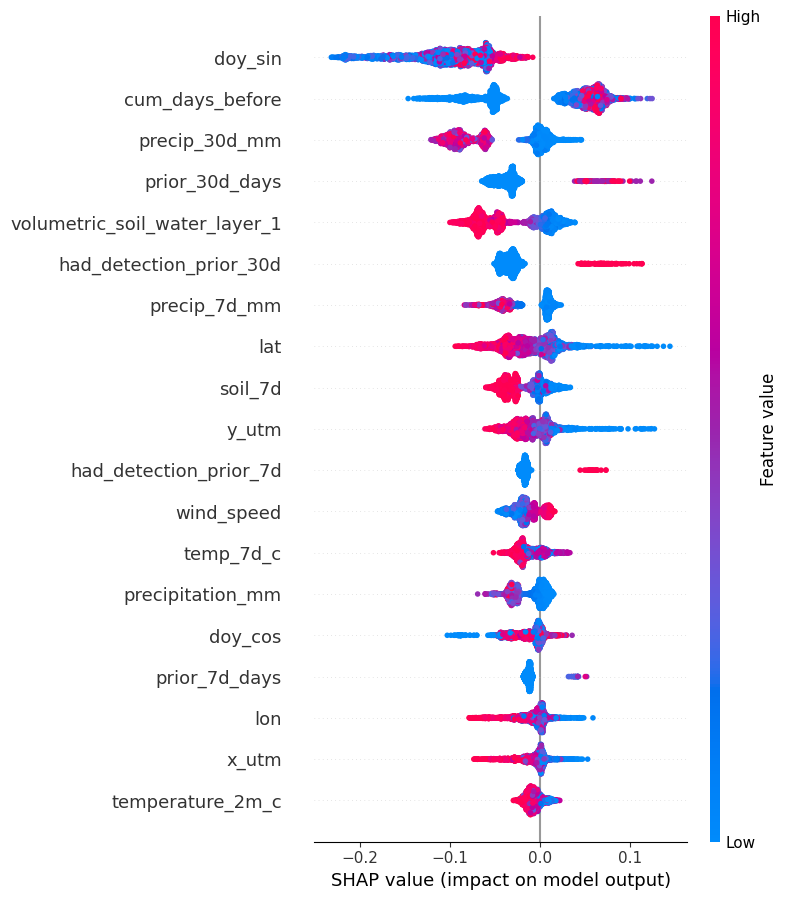


Cell UK_215000_3290000 | score 0.77 | High
                feature  value   shap      effect
         prior_30d_days  4.000  0.086 raises risk
had_detection_prior_30d  1.000  0.071 raises risk
        cum_days_before  8.000  0.060 raises risk
 had_detection_prior_7d  1.000  0.059 raises risk
                doy_sin -0.482 -0.056 lowers risk

Cell UK_450000_3370000 | score 0.01 | Low
        feature         value   shap      effect
cum_days_before      0.000000 -0.088 lowers risk
            lon     80.497002 -0.066 lowers risk
        doy_sin     -0.482000 -0.064 lowers risk
          x_utm 451731.062500 -0.063 lowers risk
 prior_30d_days      0.000000 -0.048 lowers risk


In [ ]:
!pip -q install shap
import shap, matplotlib.pyplot as plt

explainer = shap.TreeExplainer(model)

def sv_pos(X):
    sv = explainer.shap_values(X)
    if isinstance(sv, list): sv = sv[1]       # older shap versions
    elif sv.ndim == 3: sv = sv[:, :, 1]       # newer shap versions
    return sv

# Global view: 3,000 random rows from the held-out Jul-Dec 2024 period
samp = D[D.split == "test"].sample(3000, random_state=42)
Xs = samp[FEATURES].astype("float32")
plt.figure()
shap.summary_plot(sv_pos(Xs), Xs, show=False)
plt.tight_layout()
plt.savefig(f"{BASE}/Results/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

# Local view: why did one cell get its score?
def explain_cell(cell_id, df=day, n=5):
    row = df[df.cell_id == cell_id]
    X1 = row[FEATURES].astype("float32")
    s = sv_pos(X1)[0]
    out = pd.DataFrame({"feature": FEATURES, "value": X1.iloc[0].values, "shap": s})
    out = out.reindex(out.shap.abs().sort_values(ascending=False).index).head(n)
    out["effect"] = np.where(out.shap > 0, "raises risk", "lowers risk")
    print(f"\nCell {cell_id} | score {row.score.iloc[0]:.2f} | {row.risk_level.iloc[0]}")
    print(out.round(3).to_string(index=False))

explain_cell(day.sort_values("score", ascending=False).cell_id.iloc[0])
explain_cell(day.sort_values("score").cell_id.iloc[0])